In [5]:
import os.path

import pandas as pd
from glob import glob
import re
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import json
import torch
import numpy as np
from bbox_annotation import Annotation, annotation_from_json
from sklearn.model_selection import train_test_split
import cv2

import matplotlib.pyplot as plt
from tool import crop_rgb

In [6]:
%store -r data_df

In [7]:
data_df

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
0,MC765_P011_ST00BP00_5inchMD_Depth_MudLog_3686-...,/home/trip/PycharmProjects/HTB/dataset/images/...,1700,176000,"[377, 1623, 448, 174871]","[1134, 1623, 1171, 174871]","[79, 904, 1621, 1327]"
1,Mudlog-Trail Mtn1Palisades,/home/trip/PycharmProjects/HTB/dataset/images/...,1650,62325,"[391, 1424, 414, 62325]","[335, 1424, 391, 62325]","[75, 691, 673, 1215]"
2,Shell_AC0336_OCS-G-36102_001_ST00BP01_5inchMD_...,/home/trip/PycharmProjects/HTB/dataset/images/...,1275,143550,"[340, 1129, 400, 142323]","[400, 1129, 450, 142323]","[30, 668, 1208, 832]"
3,60817410140100_mc822#10bp01 1-240 tvd mud log,/home/trip/PycharmProjects/HTB/dataset/images/...,1534,163220,"[236, 1205, 316, 163204]","[953, 1205, 1000, 163204]","[2, 594, 1532, 1000]"
4,0000000009_d-582_0000020435-0001_log06_fe_5in_md,/home/trip/PycharmProjects/HTB/dataset/images/...,4864,12050,"[1288, 4404, 1376, 11195]","[2991, 4404, 3237, 11195]","[1943, 1513, 3035, 2655]"
5,60811405800300_mdn-1_st01bp01_5 inch tvdmudlog...,/home/trip/PycharmProjects/HTB/dataset/images/...,1275,120450,"[265, 1185, 325, 119853]","[932, 1185, 980, 119853]","[60, 452, 1210, 768]"
6,60817411400100_mc761_1_st1_mudlog_1tvd_17129_2...,/home/trip/PycharmProjects/HTB/dataset/images/...,1275,8250,"[255, 2197, 288, 8198]","[938, 2197, 995, 8198]","[0, 972, 918, 1400]"
7,MC765_P011_ST00BP01_5inchMD_Depth_MudLog_18230...,/home/trip/PycharmProjects/HTB/dataset/images/...,1700,35200,"[377, 1623, 448, 33669]","[1134, 1623, 1171, 33669]","[79, 904, 1621, 1327]"
8,60811406050000_608114060500_g31765 001 st00 bp...,/home/trip/PycharmProjects/HTB/dataset/images/...,1680,238000,"[278, 1628, 343, 233912]","[1167, 1628, 1230, 233912]","[2, 600, 1538, 1021]"
9,60811405800100_mdn-1_st00bp01_5 inch tvdmudlog...,/home/trip/PycharmProjects/HTB/dataset/images/...,1534,187600,"[275, 1575, 355, 187576]","[1165, 1575, 1228, 187576]","[2, 599, 1532, 1002]"


In [8]:
example_row = data_df[data_df["Name"]=="608114075800 - Allegheny Attic GC297 #3 OCS-G 08876 003 ST00 BP00  Mud Log 3346ft-13925ft MD"].iloc[0]

In [ ]:
Image.open(example_row["Image"])

In [9]:
colbounds = example_row["Interpreted Lithology Column"]

In [10]:
column = crop_rgb(Image.open(example_row["Image"]), colbounds)



In [14]:
column

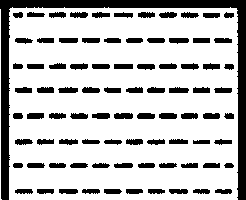

75.93292682926828 % of pixels are black


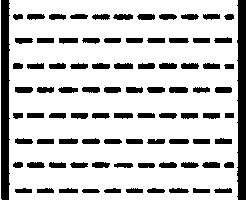

79.19918699186992 % of pixels are black


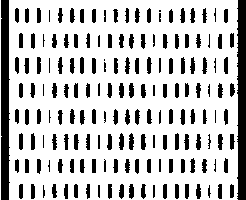

77.40853658536585 % of pixels are black


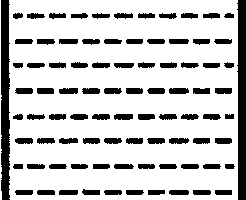

79.10365853658536 % of pixels are black


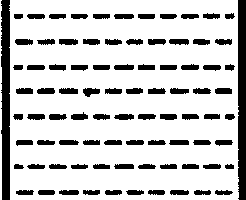

79.5691056910569 % of pixels are black


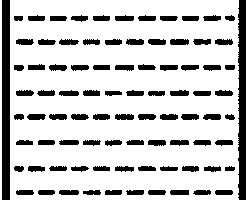

79.55081300813008 % of pixels are black


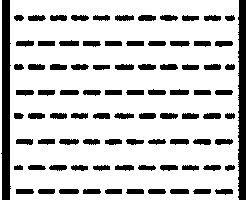

79.53455284552845 % of pixels are black


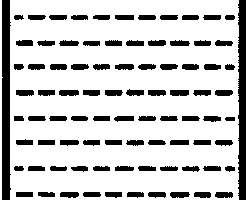

79.41056910569105 % of pixels are black


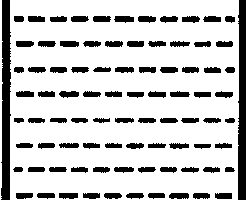

79.38821138211381 % of pixels are black


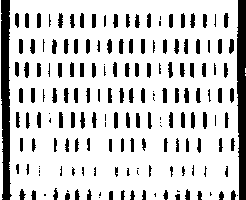

80.82723577235772 % of pixels are black


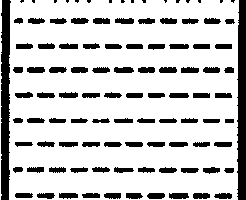

79.5081300813008 % of pixels are black


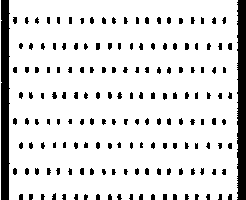

86.48373983739837 % of pixels are black


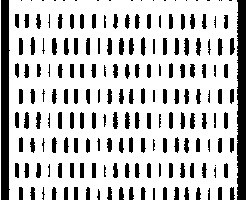

76.76626016260163 % of pixels are black


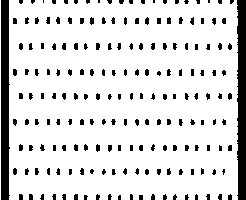

86.30894308943088 % of pixels are black


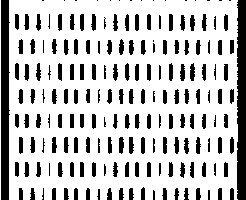

76.95731707317073 % of pixels are black


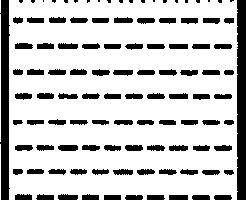

78.64837398373984 % of pixels are black


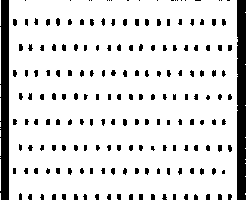

86.27235772357723 % of pixels are black


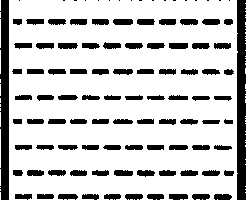

78.98373983739837 % of pixels are black


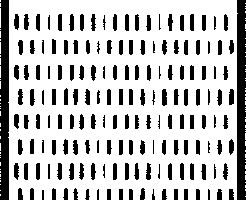

76.57317073170732 % of pixels are black


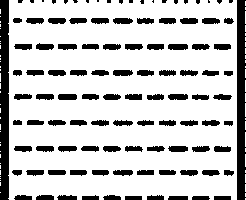

78.58739837398375 % of pixels are black


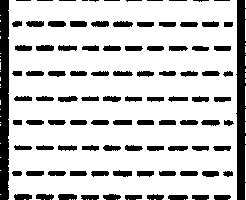

79.26219512195122 % of pixels are black


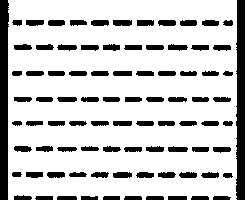

79.6260162601626 % of pixels are black


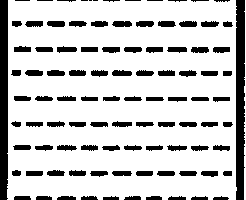

79.7459349593496 % of pixels are black


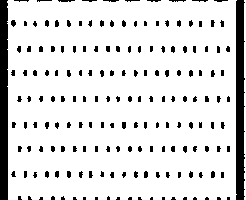

87.09146341463415 % of pixels are black


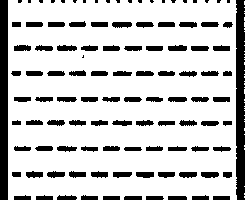

79.72967479674796 % of pixels are black


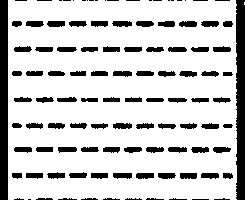

80.59959349593497 % of pixels are black


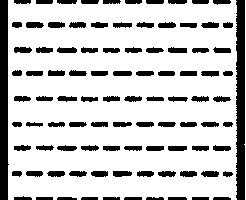

79.07520325203252 % of pixels are black


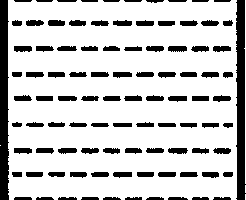

79.6849593495935 % of pixels are black


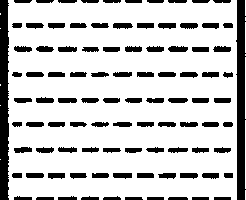

79.42479674796748 % of pixels are black


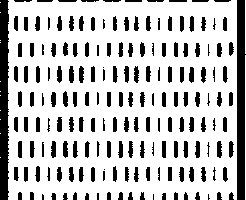

77.01626016260163 % of pixels are black


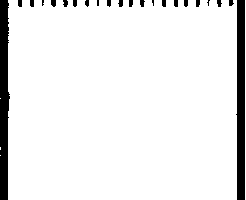

92.48170731707317 % of pixels are black


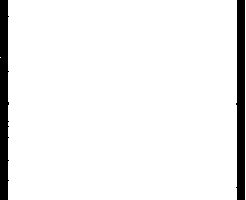

93.47154471544715 % of pixels are black


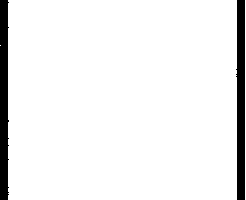

93.47154471544715 % of pixels are black


In [51]:
x, y = column.size
top = 0
bounding = 200
black = (255, 255, 255)
white = (0, 0 ,0)
for bottom in range(bounding, y+1, bounding):
    box = column.crop( (0, top, x, bottom) )
    display(box)
    w = box.size[0]
    h = box.size[1]
    pixels = box.load()
    counter = 0
    for by in range(h):
        for bx in range(w):
            if pixels[bx, by] == black:
                counter += 1
    print(counter / (bounding*x) * 100, "% of pixels are black")
    top += bounding




In [23]:
example_row["Interpreted Lithology Column"]

[2991, 4404, 3237, 11195]